# 03 · The poem MDP and the reward

Structure: **setup** (MDP definition, termination and horizon) → **reward** (components, Markov check, worked
examples) → **training probes** (the reward hacks and failure modes we actually hit, and how we fixed them) →
**discussion**.

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from poet import experiments as X, haiku, evaluate as ev, stats
from poet.haiku import RewardConfig, HaikuMDP, TARGETS, TOLERANCE
from poet.policy import TabularSoftmax, rollout

SEED = 0
lm = X.get_lm()   # the bigram of notebook 01 (V = 500, k = 0.1)
CACHE = X.RESULTS_DIR / '03_reward_design.pkl'
plt.rcParams['figure.dpi'] = 110
print('vocabulary size V =', lm.V)

vocabulary size V = 500


## 1. The MDP

One episode = one poem. The agent writes one token per step.

| | |
|---|---|
| **State** $S_t$ | $(\text{prev},\ \text{line},\ \text{syl},\ \text{exact})$: previous token (`<s>` at the start of every line), line index $\in\{0,1,2\}$, syllables so far in the current line, and a flag "all previous lines were exact" |
| **Action** $A_t$ | one of the $V=500$ words, or `</s>` = end of line |
| **Transition** | deterministic. A word adds its syllables. `</s>` ends the line. A line that exceeds its target by more than $2$ syllables is **force-ended**. After a line ends, prev resets to `<s>` and syl to 0. The 3rd line end is terminal. |
| **Reward** | dense, see §2. Undiscounted ($\gamma=1$). |

**Why the flag.** The completion bonus is paid when the poem ends *and all three lines were exact*. Without the
flag, the last step's reward would depend on lines the state no longer remembers, so the reward would not be a
function of $(S_t, A_t)$ and the process would not be Markov.

**Termination and horizon.** Every word has $\ge 1$ syllable (notebook 01), so every word action increases syl.
A line is therefore over after at most $\text{target}+2+1$ steps: either `</s>` at $\text{syl}\le\text{target}+2$, or a forced end
when syl first exceeds $\text{target}+2$. Hence

$$T = (5+3) + (7+3) + (5+3) = 26$$

is the maximum episode length, and every episode terminates. For the finite-horizon estimators, an episode of
length $L<T$ is treated as a length-$T$ episode with zero reward after the end (notebook 02). The rollout code
also asserts that no episode is longer than $T$. It never fires, as checked below on 20 000 episodes
of the bigram and of the uniform policy. The uniform policy is the one that overflows most often.

In [2]:
env = HaikuMDP(lm)
print('horizon T =', env.horizon)
n_states = (lm.V + 1) * sum((t + TOLERANCE + 1) * (2 if i else 1) for i, t in enumerate(TARGETS))
print(f'reachable-state upper bound: {n_states:,} states x {env.n_actions} actions '
      f'= {n_states * env.n_actions:,} table entries (only visited rows are stored)')

rng = np.random.default_rng(SEED)
for name, logits in [('bigram', env.bigram_logits(1.0)), ('uniform', env.uniform_logits())]:
    pol = TabularSoftmax(logits, 1.0)
    lengths = [len(rollout(env, pol, rng)) for _ in range(10_000)]
    print(f'{name:8s} episode length: mean {np.mean(lengths):.1f}, max {max(lengths)} (T = {env.horizon})')

horizon T = 26
reachable-state upper bound: 22,044 states x 501 actions = 11,044,044 table entries (only visited rows are stored)


bigram   episode length: mean 20.1, max 26 (T = 26)


uniform  episode length: mean 20.7, max 26 (T = 26)


## 2. The reward

All weights live in one place, `poet.haiku.RewardConfig`. The final design (the defaults) has these terms:

| term | when | value | depends on |
|---|---|---|---|
| syllable progress | every word | $w\,(\lvert T_\ell-\text{syl}\rvert - \lvert T_\ell-\text{syl}'\rvert)$ | syl, line, $A$ |
| exact-line bonus | line end | $+3$ if $\text{syl}=T_\ell$ | syl, line, $A$ |
| overflow penalty | forced line end | $-1$ | syl, line, $A$ |
| completion bonus | poem end | $+10$ if all three lines exact | exact flag, syl, line, $A$ |
| fluency | every step | $\lambda \log P_{\text{bigram}}(A\mid\text{prev})$, $\lambda=0.03$ | prev, $A$ |
| repeated word | every word | $-2$ if $A=\text{prev}$ | prev, $A$ |
| KL to the bigram | every step | $-\eta\,(\log\pi_\theta(A\mid S)-\log P_{\text{bigram}}(A\mid\text{prev}))$, $\eta=0.5$ | $S$, $A$ (and $\theta$) |

Every term is a function of the current state and action only, so the reward is **Markov** in the enriched state.
The KL term also depends on the current policy. Following the usual practice, it is added to the reward
and treated as a constant when computing the gradient. Evaluation always reports the **task return**, without the
KL term. We call its coefficient **η**, not β, because β is the critic step size of the actor-critic
(notebook 04). In the code it is `RewardConfig.kl_coef`.

**Syllable progress vs. a line-end score.** The initial design paid $-w\lvert\text{syl}_{\text{end}}-T_\ell\rvert$ once per line. The
per-word progress term telescopes over a line to $w\,(T_\ell-\lvert\text{syl}_{\text{end}}-T_\ell\rvert)$, which is the line-end score plus
the constant $wT_\ell$. Over a poem the two rewards differ by exactly $17w$, for **every** trajectory, so they define
the same optimal policy and the same policy gradient in expectation. What changes is *when* the information
arrives. A word that overshoots is penalised at the step where it is written, and GPOMDP and the critic can use
that. The check below confirms the constant difference numerically.

In [3]:
env_prog = HaikuMDP(lm, RewardConfig(progress=True, kl_coef=0))
env_end = HaikuMDP(lm, RewardConfig(progress=False, kl_coef=0))
pol = TabularSoftmax(env_prog.bigram_logits(1.0), 1.0)
rng = np.random.default_rng(SEED)
diffs = []
for _ in range(2000):
    tr = rollout(env_prog, pol, rng)
    r_end = sum(env_end.step(s, a)[1] for s, a in zip(tr.states, tr.actions))
    diffs.append(tr.task_ret - r_end)
print(f'return(progress) - return(line-end score): min {min(diffs):.6f}, max {max(diffs):.6f}  (17 w = 17)')

return(progress) - return(line-end score): min 17.000000, max 17.000000  (17 w = 17)


### Worked examples

A step-by-step breakdown of four hand-written poems under the final reward (KL omitted, since it depends on the
policy): a valid haiku, a poem of short lines, a poem with an overflowing line, and one with a repeated word.
Each row is one step.

In [ ]:
def breakdown(text, cfg=RewardConfig(kl_coef=0)):
    env = HaikuMDP(lm, cfg)
    actions, s, total = env.encode(text), env.reset(), 0.0
    print(f'"{text}"')
    print(f'  {"state (prev, line, syl, exact)":34s} {"action":10s} {"reward terms":58s} {"r":>6s}')
    for a in actions:
        terms = env.reward_terms(s, a)
        r = sum(terms.values())
        total += r                                                          
        prev = '<s>' if s[0] == lm.BOS else lm.vocab[s[0]]
        shown = ' '.join(f'{k}={v:+.2f}' for k, v in terms.items() if v != 0)
        print(f'  ({prev:>9s}, {s[1]}, {s[2]}, {s[3]}){"":12s} {lm.words([a])[0]:10s} {shown:58s} {r:+6.2f}')
        s, _ = env.transition(s, a)
        if s is None:
            break
    print(f'  -> return {total:.2f}   poem: {env.format_poem(actions)}\n')

breakdown('morning on the sea / ulysses sat by the ship / tears in the black night')

"morning on the sea / ulysses sat by the ship / tears in the black night"
  state (prev, line, syl, exact)     action     reward terms                                                    r
  (      <s>, 0, 0, 1)             morning    fluency=-0.36 syllables=+2.00                               +1.64
  (  morning, 0, 2, 1)             on         fluency=-0.13 syllables=+1.00                               +0.87
  (       on, 0, 3, 1)             the        fluency=-0.03 syllables=+1.00                               +0.97
  (      the, 0, 4, 1)             sea        fluency=-0.13 syllables=+1.00                               +0.87
  (      sea, 0, 5, 1)             /          fluency=-0.06 exact_line=+3.00                              +2.94
  (      <s>, 1, 0, 1)             ulysses    fluency=-0.16 syllables=+3.00                               +2.84
  (  ulysses, 1, 3, 1)             sat        fluency=-0.15 syllables=+1.00                               +0.85
  (      sat, 1, 4, 1)      

In [5]:
breakdown('the ground / the plain / the plain')
breakdown('the son of the king of the sea / ulysses sat by the ship / tears in the black night')
breakdown('morning on the sea sea / ulysses sat by the ship / tears in the black night')

"the ground / the plain / the plain"
  state (prev, line, syl, exact)     action     reward terms                                                    r
  (      <s>, 0, 0, 1)             the        fluency=-0.07 syllables=+1.00                               +0.93
  (      the, 0, 1, 1)             ground     fluency=-0.11 syllables=+1.00                               +0.89
  (   ground, 0, 2, 1)             /          fluency=-0.02                                               -0.02
  (      <s>, 1, 0, 0)             the        fluency=-0.07 syllables=+1.00                               +0.93
  (      the, 1, 1, 0)             plain      fluency=-0.12 syllables=+1.00                               +0.88
  (    plain, 1, 2, 0)             /          fluency=-0.02                                               -0.02
  (      <s>, 2, 0, 0)             the        fluency=-0.07 syllables=+1.00                               +0.93
  (      the, 2, 1, 0)             plain      fluency=-0.12 sylla

Notes on the examples:

- The valid haiku collects the full progress reward ($5+7+5=17$), three exact-line bonuses and the completion
  bonus, minus a small fluency cost.
- In the overflowing example the line is **force-ended** at the 8th syllable, the first time it exceeds $5+2$. The
  last written word (*sea*) is the one that triggers it, and no `</s>` is needed. The overflow costs the overflow penalty, the negative progress of the overshooting words, and the exact-line and
  completion bonuses. The flag goes to 0, so even a perfect 2nd and 3rd line cannot earn the completion bonus.
- *sea sea* makes line 1 six syllables and costs the repeated-word penalty.

## 3. Reward hacks and failure modes we actually found

We tuned the reward by training **GPOMDP + $b_t$** (batch 10) for 50 000 episodes and reading the poems it produced.
The runs below replay that history, from the initial design to the final one. All poems are printed from the cached
results, which are regenerated if `results/03_reward_design.pkl` is deleted.

| design | syllable reward | fluency $\lambda$ | bonuses (line / poem) | overflow | KL $\eta$ |
|---|---|---|---|---|---|
| **v0** initial | line-end score | 0.1 | 2 / 5 | 2 | 0 |
| **v0 + progress** | per-word progress | 0.1 | 2 / 5 | 2 | 0 |
| **v0, $\lambda=0.03$** | line-end score | 0.03 | 2 / 5 | 2 | 0 |
| **final** (KL sweep) | per-word progress | 0.03 | 3 / 10 | 1 | 0 … 1 |

In [6]:
V0 = dict(syllable_weight=1.0, exact_line_bonus=2.0, poem_bonus=5.0, fluency_weight=0.1,
          repeat_penalty=2.0, overflow_penalty=2.0, progress=False, kl_coef=0.0)
N_EP = 50_000
probe_specs = {
    'v0 (initial)':       dict(reward=V0, alpha=0.1),
    'v0 + progress':      dict(reward={**V0, 'progress': True}, alpha=0.3),
    'v0, lambda = 0.03':  dict(reward={**V0, 'fluency_weight': 0.03}, alpha=0.3),
}
ETAS = [0.0, 0.1, 0.3, 0.5, 1.0]
SEEDS = [0, 1, 2]
kl_specs = {(b, s): dict(reward={'kl_coef': b}, alpha=1.0, seed=s) for b in ETAS for s in SEEDS}
common = dict(method='gpomdp_b', n_episodes=N_EP, eval_every=1000)

all_specs = [{**common, **s} for s in probe_specs.values()] + [{**common, **s} for s in kl_specs.values()]
results = X.run_many(all_specs, CACHE)
probe = dict(zip(probe_specs, results[:len(probe_specs)]))
kl_runs = dict(zip(kl_specs, results[len(probe_specs):]))

def show(res, k=5):
    m = res['final_metrics']
    print(f"  final: return {m['return']:.1f} | valid {m['valid']:.0%} | distinct poems {m['distinct_poems']:.0%} | "
          f"vocab used {m['distinct_words']:.0%} | syllable error/line {m['syl_error']:.2f} | overflow {m['overflow']:.0%}")
    for poem, n in res['final_poems'][:k]:
        print(f'  {n:4d}x  {poem}')

for name, res in probe.items():
    print(f'\n=== {name}  (alpha = {res["spec"]["alpha"]})')
    show(res)

all 18 runs loaded from 03_reward_design.pkl

=== v0 (initial)  (alpha = 0.1)
  final: return -13.1 | valid 0% | distinct poems 0% | vocab used 1% | syllable error/line 3.67 | overflow 0%
   200x  the ground (2) / the skies (2) / the ground (2)

=== v0 + progress  (alpha = 0.3)
  final: return 4.6 | valid 0% | distinct poems 0% | vocab used 1% | syllable error/line 3.33 | overflow 0%
   200x  the plain (2) / and the plain (3) / the plain (2)

=== v0, lambda = 0.03  (alpha = 0.3)
  final: return -3.1 | valid 0% | distinct poems 0% | vocab used 2% | syllable error/line 1.33 | overflow 0%
   200x  he was of the ground (5) / but the grecian train (5) / the fire (3)


In [7]:
# Reference returns under the initial reward v0
env_v0 = HaikuMDP(lm, RewardConfig(**V0))
bigram_v0 = ev.poem_metrics(env_v0, ev.sample_poems(env_v0, TabularSoftmax(env_v0.bigram_logits(1.0), 1.0), 2000,
                                                    np.random.default_rng(SEED)))
print(f"v0 return of the untrained bigram: {bigram_v0['return']:.1f}  (overflowed lines: {bigram_v0['overflow']:.0%})")
for text in ['morning on the sea / ulysses sat by the ship / tears in the black night', 'the ground / the plain / the plain']:
    acts = env_v0.encode(text); s0 = env_v0.reset(); R = 0.0
    for a in acts:
        s1, r, done = env_v0.step(s0, a); R += r; s0 = s1
    print(f'v0 return of "{text}": {R:.1f}')

v0 return of the untrained bigram: -21.1  (overflowed lines: 66%)
v0 return of "morning on the sea / ulysses sat by the ship / tears in the black night": 3.5
v0 return of "the ground / the plain / the plain": -13.1


### Hack 1: short fluent lines (the fluency term wins)

With the initial weights v0, the policy learns to write **two-word lines** of very likely bigrams, *the ground / the skies /
the ground*, and collapses onto that single poem. Under v0 this *improves* the return from about −21 (untrained bigram) to
−13. The bigram overflows about two thirds of its lines, and each overflow costs $2 + \lvert\text{error}\rvert \ge 5$, while a 2-syllable
line costs only 3–5. But it is far below a real haiku, whose v0 return is printed above.

Two things make it attractive:
1. **Fluency.** Every extra word costs $\lambda\log P$, about $-0.4$ per word at $\lambda=0.1$. And `</s>` after a frequent noun (*plain*,
   *ground*) is a very likely bigram.
2. **Safety.** Ending early is the cheapest way to avoid the large overflow penalty, and it is learned first, because the
   early-line states are visited most often. Once the policy always ends early, the rows that would teach "continue to
   exactly 5" are no longer visited, and so never trained.

The two other probes isolate the cause:
- **per-word progress alone** (λ still 0.1) does *not* fix it: *the plain / and the plain / the plain*;
- **λ = 0.03 alone** fixes it only in part. Line 1 becomes exact (*he was of the ground*, 5), but lines 2 and 3 stay short (5 and 3
  syllables), because v0's small bonuses (2 / 5) are not enough to pull them out.

The final design therefore combines $\lambda: 0.1 \to 0.03$ with larger bonuses (3 / 10) so that exactness clearly dominates fluency, and
keeps per-word progress for its earlier credit assignment.

### Hack 2: collapse onto one memorised poem, often a near miss

Without the KL term (η = 0 below), **every seed** collapses within a few thousand episodes onto a **deterministic near
miss**: one poem written every time, with one or more lines a few syllables short (*thus the war (3) / but now my sire (5) / the field
(2)*). With η = 0.1, two seeds of three do the same, e.g. *the plain (2) / not in the house of the ground (7) / the sons of the ground (5)*,
where only the first line is wrong. Once π is deterministic, the better alternatives are never sampled, and the softmax gradient
$\propto\pi(a|s)$ vanishes. The valid rate stays at 0 for the rest of training. This is the bandit's "wrong arm" failure from notebook 02,
now in thousands of states.

A **repetition hack** comes with it: a collapsed policy re-uses a good content word in several lines, e.g. *i am in the ground /
ulysses said and the ground / no one of the ground* (η = 0.3). The adjacent-repeat penalty cannot see it, because it only compares a
word with the previous one.

### Fix: KL penalty to the bigram, and its price

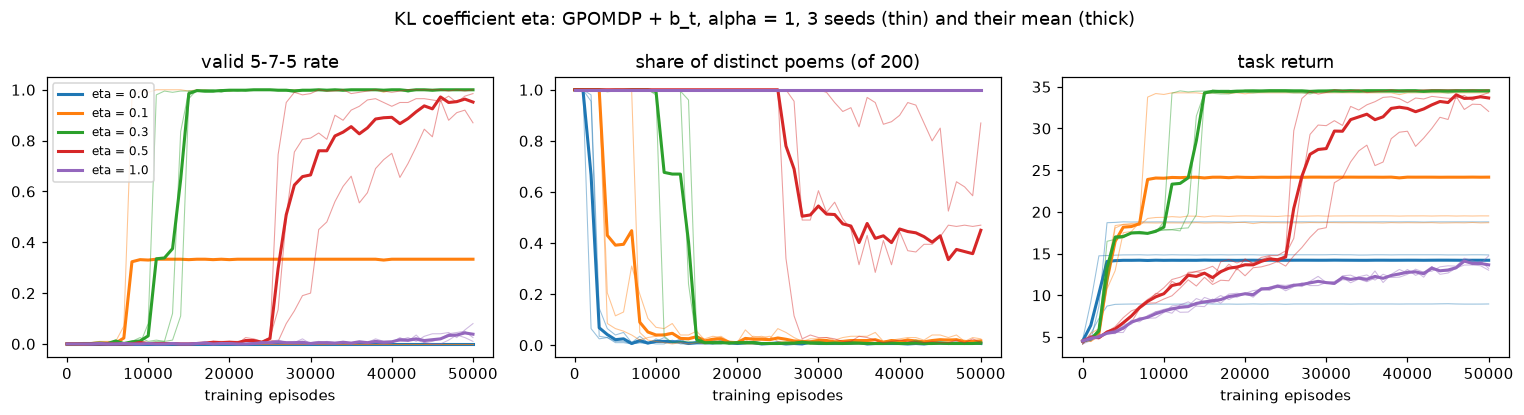

  eta   valid  distinct  vocab used    first ep. valid>=0.9 (per seed)
  0.0      0%        0%          2%                 [None, None, None]
  0.1     33%        1%          3%                 [None, 8000, None]
  0.3    100%        1%          2%              [11000, 15000, 15000]
  0.5     96%       43%         21%              [33000, 27000, 46000]
  1.0      6%      100%         94%                 [None, None, None]


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for k, b in enumerate(ETAS):
    runs = [kl_runs[(b, s)] for s in SEEDS]
    x = np.array(runs[0]['history']['eval_episodes'])
    for ax, key in zip(axes, ['eval_valid', 'eval_distinct_poems', 'eval_return']):
        ys = np.array([r['history'][key] for r in runs])
        for y in ys:                                   # individual seeds (thin)
            ax.plot(x, y, color=f'C{k}', lw=0.7, alpha=0.45)
        ax.plot(x, ys.mean(axis=0), color=f'C{k}', lw=2, label=f'eta = {b}')
for ax, t in zip(axes, ['valid 5-7-5 rate', 'share of distinct poems (of 200)', 'task return']):
    ax.set_title(t); ax.set_xlabel('training episodes')
axes[0].legend(fontsize=8)
fig.suptitle(f'KL coefficient eta: GPOMDP + b_t, alpha = 1, {len(SEEDS)} seeds (thin) and their mean (thick)')
plt.tight_layout(); plt.show()

print(f'{"eta":>5s} {"valid":>7s} {"distinct":>9s} {"vocab used":>11s} {"first ep. valid>=0.9 (per seed)":>34s}')
for b in ETAS:
    runs = [kl_runs[(b, s)] for s in SEEDS]
    fm = [r['final_metrics'] for r in runs]
    first = []
    for r in runs:
        v = np.array(r['history']['eval_valid']); e = r['history']['eval_episodes']
        first.append(e[int(np.argmax(v >= 0.9))] if (v >= 0.9).any() else None)
    print(f'{b:5.1f} {np.mean([m["valid"] for m in fm]):7.0%} {np.mean([m["distinct_poems"] for m in fm]):9.0%} '
          f'{np.mean([m["distinct_words"] for m in fm]):11.0%} {str(first):>34s}')

In [9]:
for b in ETAS:
    print(f'\n=== eta = {b}, seed 0')
    show(kl_runs[(b, 0)], k=4)


=== eta = 0.0, seed 0
  final: return 9.0 | valid 0% | distinct poems 0% | vocab used 2% | syllable error/line 2.33 | overflow 0%
   200x  thus the war (3) / but now my sire (5) / the field (2)

=== eta = 0.1, seed 0
  final: return 18.7 | valid 0% | distinct poems 2% | vocab used 3% | syllable error/line 1.00 | overflow 0%
   163x  the plain (2) / not in the house of the ground (7) / the sons of the ground (5)
    36x  the plain (2) / not in the house and the ground (7) / the sons of the ground (5)
     1x  the blood his wife been better to (8) / not in the house of the ground (7) / the sons of the ground (5)

=== eta = 0.3, seed 0
  final: return 34.6 | valid 100% | distinct poems 0% | vocab used 2% | syllable error/line 0.00 | overflow 0%
   200x  i am in the ground (5) / ulysses said and the ground (7) / no one of the ground (5)

=== eta = 0.5, seed 0
  final: return 33.8 | valid 96% | distinct poems 39% | vocab used 18% | syllable error/line 0.06 | overflow 1%
    13x  the house 

In [10]:
# Is the cross-line repetition hack still there in the final design? Share of poems that repeat a
# *content* word (not among the 50 most frequent vocabulary words) anywhere in the poem.
function_words = set(range(50))       # the vocabulary is sorted by frequency
def content_repeat_rate(poems):
    total = 0; rep = 0
    for poem, n in poems:
        words = [w for line in poem.split(' / ') for w in line.rsplit(' (', 1)[0].split()]
        ids = [lm.vocab.index(w) for w in words]
        content = [i for i in ids if i not in function_words]
        rep += n * (len(content) != len(set(content))); total += n
    return rep / total

from collections import Counter
pol0 = TabularSoftmax(env.bigram_logits(1.0), 1.0)
bigram_poems = Counter(env.format_poem(tr.actions) for tr in ev.sample_poems(env, pol0, 600, np.random.default_rng(SEED))).most_common()
print(f'untrained bigram: {content_repeat_rate(bigram_poems):.0%} of poems repeat a content word')
for b in ETAS:
    rates = [content_repeat_rate(kl_runs[(b, s)]['final_poems']) for s in SEEDS]
    print(f'eta = {b}: {np.mean(rates):.0%} of poems repeat a content word (per seed: {[f"{r:.0%}" for r in rates]})')

untrained bigram: 16% of poems repeat a content word
eta = 0.0: 0% of poems repeat a content word (per seed: ['0%', '0%', '0%'])
eta = 0.1: 33% of poems repeat a content word (per seed: ['100%', '0%', '0%'])
eta = 0.3: 67% of poems repeat a content word (per seed: ['100%', '0%', '100%'])
eta = 0.5: 9% of poems repeat a content word (per seed: ['10%', '0%', '18%'])
eta = 1.0: 10% of poems repeat a content word (per seed: ['8%', '14%', '8%'])


### Reading the KL sweep

The KL penalty adds $-\eta\,\mathrm{KL}(\pi_\theta(\cdot|s)\,\|\,P_{\text{bigram}}(\cdot|\text{prev}))$ per step in expectation. Its maximiser is
$\pi \propto P_{\text{bigram}}\,\exp(Q/\eta)$, so it keeps the policy stochastic **only when η is comparable to the gaps between
action values**. Those gaps are several reward units here (exact vs. not exact).

- **η = 0:** collapse onto a near miss in every seed (0% valid). **η = 0.1:** the same in two seeds of three.
- **η = 0.3:** still collapses onto a single poem, but now onto a **valid** one, in every seed and fast (11–15k episodes to a
  90% valid rate). The extra stochasticity lasts just long enough to find exact lines before the policy freezes.
- **η = 0.5 (chosen):** valid in every seed (≈96% at the end; 27–46k episodes to 90%) and keeps a large **share** of distinct poems
  (≈43% of 200 at the end, using ≈21% of the vocabulary). The poems vary in a few words around a learned skeleton, e.g. *the house of
  the gods / shore / plain*.
- **η = 1:** every poem stays distinct and most of the vocabulary is used, but after 50k episodes only ~6% of poems are valid. The KL term contains $+\eta\log P_{\text{bigram}}$, a fluency reward
  30 times larger than $\lambda$. It pulls the policy back toward the bigram, which overflows its lines.

So diversity and sample complexity trade off: the tabular policy learns fastest by memorising. η = 0.5 is the compromise
used in the rest of the project.

### A poem-level "no repeated words" penalty (not added)

The cross-line repetition hack could be removed by penalising any word already used in the poem. That reward depends on
the whole history, so it is **not Markov** in our state (which only stores the previous word).
- **GPOMDP stays unbiased.** Its derivation only uses the fact that the reward at time $t$ does not depend
  on *future* actions, and a history-dependent reward still satisfies that. REINFORCE does not need the Markov property at all.
- **The tabular critic suffers from state aliasing.** Two histories that reach the same state $(\text{prev}, \text{line}, \text{syl}, \text{exact})$ have
  different futures (different words are "used up"), but $V_w$ must give them one value. The TD target is then biased, and
  so is the advantage estimate $\delta_t$.

We did not add this penalty. The measurement above shows that cross-line repetition is mostly a property of **collapsed**
policies: it occurs in every poem of the collapsed η = 0.1 / 0.3 runs that memorised such a poem. With the final η = 0.5, about 9%
of poems repeat a content word (0–18% depending on the seed), fewer than the untrained bigram (16%). Keeping the reward Markov also means all five methods optimise exactly the
same MDP, and the critic is not handicapped by aliasing.

## 4. Discussion

- The MDP is finite-horizon ($T=26$) by construction, so termination never relies on the policy. Every reward term was
  checked against the state, and the reward is Markov.
- The dangerous parts of the reward were the **fluency term**, which rewards short, generic lines, and the absence of anything
  that keeps the policy stochastic, which leads to memorisation and near-miss lock-in. Both were found by reading poems, not
  by reading the return curve: hack 1 *increases* the return.
- Final design: per-word syllable progress, exact-line bonus 3, completion bonus 10, overflow −1, repeat −2,
  $\lambda = 0.03$, KL η = 0.5.